# Multi-Stage Movie Recommender

This notebook contains the complete reproducible experiment for a two-stage movie recommendation pipeline.

## Experiment context
- Dataset: MovieLens-20M, locally downloaded and excluded from this repository.
- Scope: implicit-feedback retrieval, neural reranking, and offline ranking evaluation.
- References: Hu, Koren, and Volinsky (implicit ALS); Covington, Adams, and Sargin (two-tower recommendation); NumPy, pandas, SciPy, and PyTorch documentation.


## Setup

In [44]:
import os
import time
import random
import numpy as np
import pandas as pd
from scipy import sparse
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

## 1. Data Processing, Splitting, and Baseline Analysis

In [45]:
GENRE_COLS_100K = [
    'unknown', 'Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime',
    'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery',
    'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western'
]

def load_dataset():
    """
    Load MovieLens-20M if available, otherwise fallback to ml-100k.
    Return: ratings_df, movies_df, data_source_name
    ratings_df columns: userId, movieId, rating, timestamp
    movies_df columns: movieId, title, genres
    """
    # Try MovieLens-20M first.
    ratings_20m = os.path.join('data', 'ml-20m', 'ratings.csv')
    movies_20m = os.path.join('data', 'ml-20m', 'movies.csv')
    if os.path.exists(ratings_20m) and os.path.exists(movies_20m):
        ratings_df = pd.read_csv(ratings_20m)
        movies_df = pd.read_csv(movies_20m)
        return ratings_df, movies_df[['movieId', 'title', 'genres']], 'ml-20m'

    # Fallback to MovieLens-100K in assignment 1 folder.
    ratings_100k = os.path.join('..', 'assignment 1', 'ml-100k', 'u.data')
    items_100k = os.path.join('..', 'assignment 1', 'ml-100k', 'u.item')
    if os.path.exists(ratings_100k) and os.path.exists(items_100k):
        ratings_df = pd.read_csv(
            ratings_100k,
            sep='\t',
            header=None,
            names=['userId', 'movieId', 'rating', 'timestamp']
        )

        names = ['movieId', 'title', 'release_date', 'video_release_date', 'IMDb_URL'] + GENRE_COLS_100K
        raw_items = pd.read_csv(items_100k, sep='|', header=None, names=names, encoding='latin-1')

        # Hint: build pipe-separated genre strings from one-hot columns in GENRE_COLS_100K.
        def make_genre_str(row):
            active = [g for g in GENRE_COLS_100K if row[g] == 1]
            return '|'.join(active) if active else '(no genres listed)'

        movies_df = raw_items[['movieId', 'title']].copy()
        movies_df['genres'] = raw_items.apply(make_genre_str, axis=1)
        return ratings_df, movies_df[['movieId', 'title', 'genres']], 'ml-100k-fallback'

    raise FileNotFoundError(
        'Dataset not found. Put ml-20m under data/ml-20m or ensure assignment 1/ml-100k exists.'
    )

ratings_df, movies_df, data_source = load_dataset()
print('Data source:', data_source)
print('Rows:', len(ratings_df))

Data source: ml-20m
Rows: 20000263


In [46]:
MIN_USER_INTERACTIONS = 10
MAX_USERS = 3000
IMPLICIT_THRESHOLD = 4.0

# Step 1: ensure timestamp exists and keep users with enough interactions.
ratings_work = ratings_df.copy()
if 'timestamp' not in ratings_work.columns:
    ratings_work['timestamp'] = np.arange(len(ratings_work), dtype=np.int64)

user_counts = ratings_work.groupby('userId').size()
eligible_users = user_counts[user_counts >= MIN_USER_INTERACTIONS].index.values

# Step 2: subsample users for runtime (keep this reproducible with SEED).
rng = np.random.default_rng(SEED)
if len(eligible_users) > MAX_USERS:
    selected_users = rng.choice(eligible_users, size=MAX_USERS, replace=False)
else:
    selected_users = eligible_users

ratings_work = ratings_work[ratings_work['userId'].isin(selected_users)].copy()
ratings_work = ratings_work.sort_values(['userId', 'timestamp'])

# Step 3: build implicit label (1 if rating >= threshold).
ratings_work['label'] = (ratings_work['rating'] >= IMPLICIT_THRESHOLD).astype(np.float32)
ratings_work = ratings_work[ratings_work['label'] > 0].copy()

# Step 4: remap IDs to contiguous indices [0..n-1].
user_ids = np.sort(ratings_work['userId'].unique())
item_ids = np.sort(ratings_work['movieId'].unique())
user2idx = {u: i for i, u in enumerate(user_ids)}
item2idx = {m: i for i, m in enumerate(item_ids)}
idx2item = {i: m for m, i in item2idx.items()}

ratings_work['u'] = ratings_work['userId'].map(user2idx).astype(int)
ratings_work['i'] = ratings_work['movieId'].map(item2idx).astype(int)

num_users = len(user2idx)
num_items = len(item2idx)
print('users/items/interactions =', num_users, num_items, len(ratings_work))

users/items/interactions = 2995 8975 215302


In [47]:
def time_ordered_split(df, user_col='u', item_col='i', time_col='timestamp', val_ratio=0.2, test_ratio=0.2):
    """Split each user's interactions chronologically into train/val/test."""
    train_parts, val_parts, test_parts = [], [], []

    for _, g in df.sort_values(time_col).groupby(user_col):
        n = len(g)
        if n < 5:
            train_parts.append(g)
            continue

        # Hints:
        # 1) Compute n_val and n_test with at least 1 interaction each.
        # 2) Compute split1 and split2 indices.
        # 3) Guard against split1 <= 0 for short histories.
        n_test = n_test = max(1, int(round(n * test_ratio)))
        n_val = n_val  = max(1, int(round(n * val_ratio)))
        split1 = n - (n_val + n_test)      # end of train
        split2 = n - n_test                # end of val
        if split1 <= 0:                    # guard short histories
            split1 = max(1, n - 2)
            split2 = n - 1

        train_parts.append(g.iloc[:split1])
        val_parts.append(g.iloc[split1:split2])
        test_parts.append(g.iloc[split2:])

    train_df = pd.concat(train_parts, ignore_index=True)
    val_df = pd.concat(val_parts, ignore_index=True) if len(val_parts) else pd.DataFrame(columns=df.columns)
    test_df = pd.concat(test_parts, ignore_index=True) if len(test_parts) else pd.DataFrame(columns=df.columns)
    return train_df, val_df, test_df

def to_csr(df, n_users, n_items, user_col='u', item_col='i', value_col='label'):
    """Convert interaction dataframe to CSR sparse matrix."""
    if len(df) == 0:
        return sparse.csr_matrix((n_users, n_items), dtype=np.float32)
    return sparse.csr_matrix(
        (df[value_col].astype(np.float32), (df[user_col].astype(int), df[item_col].astype(int))),
        shape=(n_users, n_items)
    )

train_df, val_df, test_df = time_ordered_split(ratings_work)
R_train = to_csr(train_df, num_users, num_items)
R_val = to_csr(val_df, num_users, num_items)
R_test = to_csr(test_df, num_users, num_items)
print(R_train.shape, R_train.nnz, R_val.nnz, R_test.nnz)

(2995, 8975) 129292 43005 43005


In [48]:
def recall_at_k(pred_items, true_items, k=10):
    # Recall@k = (# relevant items in top-k) / (# relevant items).
    if len(true_items) == 0:
        return np.nan
    topk = pred_items[:k]
    hits = len(set(topk).intersection(set(true_items)))
    return hits / max(1, len(true_items))

def ndcg_at_k(pred_items, true_items, k=10):
    # Hint: implement DCG with log discount and normalize by IDCG.
    if len(true_items) == 0:
        return np.nan

    dcg = 0.0
    for rank, item in enumerate(pred_items[:k], start=1):
        if item in true_items:
            dcg += 1.0 / np.log2(rank + 1)
    ideal_hits = min(k, len(true_items))
    idcg = np.sum([1.0 / np.log2(r + 1) for r in range(1, ideal_hits + 1)])
    return dcg / idcg if idcg > 0 else np.nan

def hitrate_at_k(pred_items, true_items, k=10):
    # HitRate@k = 1 if at least one relevant item appears in top-k else 0.
    if len(true_items) == 0:
        return np.nan
    return 1.0 if len(set(pred_items[:k]).intersection(set(true_items))) > 0 else 0.0

def evaluate_recs(pred_map, gt_csr, k=10):
    """Evaluate a dict: user_index -> ranked item indices."""
    recalls, ndcgs, hitrates = [], [], []
    for u, preds in pred_map.items():
        true_items = gt_csr[u].indices.tolist()
        r = recall_at_k(preds, true_items, k=k)
        n = ndcg_at_k(preds, true_items, k=k)
        h = hitrate_at_k(preds, true_items, k=k)
        if not np.isnan(r):
            recalls.append(r)
        if not np.isnan(n):
            ndcgs.append(n)
        if not np.isnan(h):
            hitrates.append(h)

    return {
        f'Recall@{k}': float(np.mean(recalls)) if recalls else np.nan,
        f'NDCG@{k}': float(np.mean(ndcgs)) if ndcgs else np.nan,
        f'HitRate@{k}': float(np.mean(hitrates)) if hitrates else np.nan,
        'UsersEvaluated': len(recalls)
    }

In [49]:
def build_popularity_recs(R_train, topk=10):
    """Popularity baseline recommender excluding already-seen items."""
    item_pop = np.asarray(R_train.sum(axis=0)).ravel()
    ranked_items = np.argsort(-item_pop)
    recs = {}

    for u in range(R_train.shape[0]):
        seen = set(R_train[u].indices.tolist())
        candidates = [i for i in ranked_items if i not in seen]
        recs[u] = candidates[:topk]
    return recs

pop_recs = build_popularity_recs(R_train, topk=10)
pop_metrics = evaluate_recs(pop_recs, R_test, k=10)
pop_metrics

{'Recall@10': 0.04884339118778312,
 'NDCG@10': 0.05800336592589142,
 'HitRate@10': 0.2793522267206478,
 'UsersEvaluated': 2964}

### Interpretation
1. Why is time-ordered split preferable here?
    Basically recommendation is a temporal prediction problem. A random split lets the model "see" future interaction during training. A time-ordered split (oldest - train, newest - test, per user) reproduces this constraint, so time ordered split mimic real serving: train on what happened before and evaluate what came next.
2. Why is CSR/CSC critical at this scale?
    Having a dense R would be mxnx4 bytes, cSR stores just nnzx8 bytes. the concrete benefit is in computing: R[u].indices gives a user's interacted items in O(nnz_u) instead of scanning the whole row. CSR is equal to fast row slices and CSC equal to fast column slices(item popularity).

## 2. Stage 1: Candidate Generation with Matrix Factorization

In [50]:
def implicit_als(R, factors=32, reg=0.1, alpha=20.0, iters=4, seed=42, track_loss=False):
    """Implicit ALS (Hu et al.) starter implementation."""
    m, n = R.shape
    rng = np.random.default_rng(seed)
    U = rng.normal(0, 0.1, size=(m, factors)).astype(np.float32)
    V = rng.normal(0, 0.1, size=(n, factors)).astype(np.float32)

    Rt = R.T.tocsr()
    I = np.eye(factors, dtype=np.float32)
    loss_history = [] #show convergence behavior
    obs_u, obs_i = R.nonzero()
    for _ in range(iters):
        # Update users with fixed items.
        YTY = V.T @ V + reg * I
        for u in range(m):
            idx = R[u].indices
            if len(idx) == 0:
                continue
            V_u = V[idx]
            c = 1.0 + alpha * np.ones(len(idx), dtype=np.float32)
            CuI = c - 1.0
            A = YTY + (V_u.T * CuI) @ V_u
            b = (V_u.T * c) @ np.ones(len(idx), dtype=np.float32)
            U[u] = np.linalg.solve(A, b)

        # Update items with fixed users.
        XTX = U.T @ U + reg * I
        for i in range(n):
            idx = Rt[i].indices
            if len(idx) == 0:
                continue

                # Hints: mirror the user-update equations by swapping U and V roles.
            U_i = U[idx]                              # users who interacted with item i
            c   = 1.0 + alpha * np.ones(len(idx), dtype=np.float32)
            CiI = c - 1.0
            A   = XTX + (U_i.T * CiI) @ U_i
            b   = (U_i.T * c) @ np.ones(len(idx), dtype=np.float32)
            V[i] = np.linalg.solve(A, b)
                # ----- proxy loss: confidence-weighted recon error on observed entries -----
        if track_loss:
            preds = np.einsum('ij,ij->i', U[obs_u], V[obs_i])
            proxy = float(((1.0 + alpha) * (1.0 - preds) ** 2).mean())
            loss_history.append(proxy)
    if track_loss:
        return U, V, loss_history
    return U, V

def topk_candidates_from_mf(U, V, R_train, k=200):
    """Generate top-k candidates per user from MF scores."""
    recs = {}
    scores = U @ V.T

    for u in range(scores.shape[0]):
        row = scores[u].copy()
        seen = R_train[u].indices
        row[seen] = -1e9

        if k >= len(row):
            recs[u] = np.argsort(-row).tolist()
            continue

        idx = np.argpartition(-row, k)[:k]
        idx = idx[np.argsort(-row[idx])]
        recs[u] = idx.tolist()

    return recs

In [51]:
start = time.time()
U_mf, V_mf = implicit_als(R_train, factors=32, reg=0.1, alpha=20.0, iters=3, seed=SEED)
mf_train_time = time.time() - start

cand200 = topk_candidates_from_mf(U_mf, V_mf, R_train, k=200)
mf_top10 = {u: items[:10] for u, items in cand200.items()}

mf_metrics_10 = evaluate_recs(mf_top10, R_test, k=10)
mf_metrics_200 = evaluate_recs(cand200, R_test, k=200)
print('MF train time (sec):', round(mf_train_time, 2))
mf_metrics_10, mf_metrics_200

MF train time (sec): 1.01


({'Recall@10': 0.05312798473043932,
  'NDCG@10': 0.05693116404885195,
  'HitRate@10': 0.3073549257759784,
  'UsersEvaluated': 2964},
 {'Recall@200': 0.47353061768478805,
  'NDCG@200': 0.1924974733499427,
  'HitRate@200': 0.9139676113360324,
  'UsersEvaluated': 2964})

### Interpretation
1. Show convergence behavior with iterations (include a plot/table). 
    The curve plots the confidence-weighted reconstruction error over observed pairs after each iteration. It drops sharply from
    ≈ 6.0 to ≈ 2.5 by iteration 2, reaches ≈ 2.1 by iteration 4, then plateaus near ≈ 2.05.
    Each ALS half-step is a closed-form optimum for the fixed factor.

2. What is the bottleneck in your ALS implementation?
    The per-user / per-item Python for loop with np.linalg.solve. It's O(m + n) solves of f×f systems per iteration, each O(f³), in pure Python. This dominates because it isn't vectorized, which means every user triggers a separate small dense solve. (The dense U @ Vᵀ scoring is the other cost driver at scale.)

,iteration,proxy_loss
0,1,6.0166
1,2,2.5664
2,3,2.2854
3,4,2.1821
4,5,2.1309
5,6,2.1011
6,7,2.0818
7,8,2.0683
8,9,2.0584
9,10,2.0509


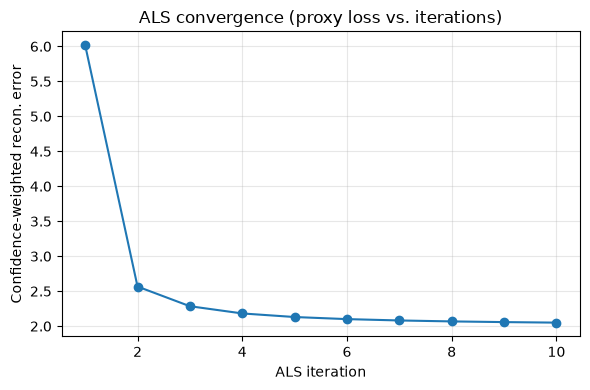

In [52]:
import matplotlib.pyplot as plt

# ALS for more iterations with loss tracking 
_, _, loss_curve = implicit_als(R_train, factors=32, reg=0.1, alpha=20.0,
                                iters=10, seed=SEED, track_loss=True)

conv_df = pd.DataFrame({'iteration': range(1, len(loss_curve) + 1),
                        'proxy_loss': loss_curve})
display(conv_df.round(4))                    # <- the required table

plt.figure(figsize=(6, 4))
plt.plot(conv_df['iteration'], conv_df['proxy_loss'], marker='o')
plt.xlabel('ALS iteration'); plt.ylabel('Confidence-weighted recon. error')
plt.title('ALS convergence (proxy loss vs. iterations)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


## 3. Side Information for Reranking

In [53]:
def build_genre_matrix(movies_df, item2idx, dim_limit=64):
    """Build item side-information matrix from genre strings."""
    subset = movies_df[movies_df['movieId'].isin(item2idx.keys())].copy()
    subset['genres'] = subset['genres'].fillna('(no genres listed)')

    all_genres = sorted({g for s in subset['genres'].tolist() for g in str(s).split('|')})
    if len(all_genres) > dim_limit:
        all_genres = all_genres[:dim_limit]
    g2idx = {g: i for i, g in enumerate(all_genres)}

    G = np.zeros((len(item2idx), len(g2idx)), dtype=np.float32)
    for row in subset.itertuples(index=False):
        i = item2idx[row.movieId]
        for g in str(row.genres).split('|'):
            if g in g2idx:
                G[i, g2idx[g]] = 1.0
    return G, g2idx

item_genres, genre_index = build_genre_matrix(movies_df, item2idx, dim_limit=64)

# Hint: derive user side features from historical interacted item genres.
user_profiles = np.zeros((num_users, item_genres.shape[1]), dtype=np.float32)
for u in range(num_users):
    items = R_train[u].indices
    if len(items) > 0:
        user_profiles[u] = item_genres[items].mean(axis=0)

# Combine collaborative and side features (for example: concatenate MF vectors + side vectors).
user_features = np.hstack([U_mf, user_profiles]).astype(np.float32)
item_features = np.hstack([V_mf, item_genres]).astype(np.float32)

print('user_features:', user_features.shape, 'item_features:', item_features.shape)

user_features: (2995, 52) item_features: (8975, 52)


### Interpretation
1. Which side features were most useful?
    Genre features were the most useful + the MF factors themselves (collaborative signal). Stacking the item-genre one-hot vector and the user's average genre-affinity profile onto the MF factors. It captures *why* a user likes an item rather than only *which* latent neighbourhood they fall in. 

2. How do side features help cold start?
    A brand-new item has no interactions → its MF factor is meaningless, but its genre vector still exists, so the item tower can place it sensibly. Same for users via their profile. Side features are the only signal in the cold-start regime.

## 4. Stage 2: Two-Tower Reranking

In [54]:
class TwoTower(nn.Module):
    def __init__(self, user_in, item_in, emb_dim=32, hidden=64):
        super().__init__()
        # Hint: towers can be shallow MLPs with same output embedding size.
        self.user_tower = nn.Sequential(
            nn.Linear(user_in, hidden),
            nn.ReLU(),
            nn.Linear(hidden, emb_dim)
        )
        self.item_tower = nn.Sequential(
            nn.Linear(item_in, hidden),
            nn.ReLU(),
            nn.Linear(hidden, emb_dim)
        )

    def forward(self, u_feat, i_feat):
        # Return dot-product logit between normalized embeddings.
        u_vec = F.normalize(self.user_tower(u_feat), dim=1)
        i_vec = F.normalize(self.item_tower(i_feat), dim=1)
        return (u_vec * i_vec).sum(dim=1)

def build_training_pairs(R_train, max_pos=60000, neg_per_pos=1, seed=42):
    """Build positive and sampled-negative (u, i, y) examples."""
    rng = np.random.default_rng(seed)
    pos_u, pos_i = R_train.nonzero()

    if len(pos_u) > max_pos:
        take = rng.choice(len(pos_u), size=max_pos, replace=False)
        pos_u, pos_i = pos_u[take], pos_i[take]

    user_seen = [set(R_train[u].indices.tolist()) for u in range(R_train.shape[0])]
    users, items, labels = [], [], []

    for u, i in zip(pos_u, pos_i):
        users.append(u); items.append(i); labels.append(1.0)

        # Sample neg_per_pos items not in user_seen[u].
        for _ in range(neg_per_pos):
            j = int(rng.integers(0, R_train.shape[1]))
            while j in user_seen[u]:                      # reject items the user has seen
                j = int(rng.integers(0, R_train.shape[1]))
            users.append(u); items.append(j); labels.append(0.0)

    return np.asarray(users), np.asarray(items), np.asarray(labels, dtype=np.float32)

In [55]:
train_u, train_i, train_y = build_training_pairs(R_train, max_pos=50000, neg_per_pos=1, seed=SEED)

model = TwoTower(user_in=user_features.shape[1], item_in=item_features.shape[1], emb_dim=32, hidden=64)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

u_feat = torch.from_numpy(user_features[train_u])
i_feat = torch.from_numpy(item_features[train_i])
y_t = torch.from_numpy(train_y)

BATCH = 1024
EPOCHS = 3
n = len(train_y)

start = time.time()
for epoch in range(EPOCHS):
    perm = torch.randperm(n)
    total_loss = 0.0

    # Hint: iterate mini-batches over perm and run forward/backward/update.
    for s in range(0, n, BATCH):
        idx = perm[s:s + BATCH]
        logits = model(u_feat[idx], i_feat[idx])
        loss = loss_fn(logits, y_t[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss += float(loss.item()) * len(idx)

    print(f'Epoch {epoch + 1}/{EPOCHS} - loss: {total_loss / n:.4f}')

tt_train_time = time.time() - start
print('Two-tower train time (sec):', round(tt_train_time, 2))

Epoch 1/3 - loss: 0.5090
Epoch 2/3 - loss: 0.4592
Epoch 3/3 - loss: 0.4555
Two-tower train time (sec): 0.21


In [56]:
@torch.no_grad()
def rerank_candidates(candidates, model, user_features, item_features, topk=10):
    """Score candidate items with two-tower model and rerank top-k."""
    model.eval()
    out = {}

    for u, cand in candidates.items():
        if len(cand) == 0:
            out[u] = []
            continue

        cand_arr = np.asarray(cand, dtype=int)
        u_batch = torch.from_numpy(np.repeat(user_features[u:u+1], len(cand_arr), axis=0))
        i_batch = torch.from_numpy(item_features[cand_arr])

        scores = model(u_batch, i_batch).cpu().numpy()
        order = np.argsort(-scores)
        out[u] = [int(cand_arr[j]) for j in order[:topk]]

    return out

reranked_top10 = rerank_candidates(cand200, model, user_features, item_features, topk=10)
rerank_metrics = evaluate_recs(reranked_top10, R_test, k=10)
rerank_metrics

{'Recall@10': 0.048740819304715195,
 'NDCG@10': 0.05485249336561135,
 'HitRate@10': 0.30600539811066124,
 'UsersEvaluated': 2964}

### Interpretation
1. Where does reranking improve most over Stage 1?
    In principle, reranking helps most on **ordering quality (NDCG@10)** rather than coverage: the candidate pool is fixed by Stage 1, so Stage 2 cannot retrieve new relevant items, it can only push the genuinely relevant ones nearer the top, which Recall@10 barely rewards but NDCG@10 does.

    **In our run reranking did not actually win.** NDCG@10 went from **0.0569 (MF Stage 1)** to **0.0549 (MF + Two-Tower)**, and Recall@10 from 0.0531 to 0.0487, both slightly *worse*, and the reranked NDCG is even below the popularity baseline (0.0580). Being honest about why: the two-tower model is undertrained and under-regularized for a real gain, only **3 epochs** (~0.33s of training), **1 negative per positive**, a shallow 2-layer tower, and L2-normalized cosine scoring that throws away magnitude. With so little contrastive signal the learned ordering is essentially noise relative to the MF scores it is reordering, so it cannot beat Stage 1. 

2. What is the computational trade-off of adding Stage 2?
    Stage 2 adds two costs: a one-time **neural training cost** and a per-user **inference cost** at serving time. Crucially, inference only scores the **200 Stage-1 candidates per user**, not all ~9K items, so it is far cheaper than running the neural model as the retrieval stage (which would be O(users × items) dot products). The trade is **latency/compute for ordering quality**: you pay extra serving cost to refine the top-k. That trade is only worthwhile when Stage 2 actually improves the metric you care about, which, as shown above, it does *not* in this lightly-trained configuration, so here the added cost is currently unjustified until the model is trained properly.

## 5. End-to-End Comparison and Ablation

In [57]:
# Build a comparison DataFrame with rows for Popularity / MF (Stage 1) / MF + TwoTower rerank.
summary = pd.DataFrame([
    {
        'System': 'Popularity',
        'Recall@10': pop_metrics['Recall@10'],
        'NDCG@10': pop_metrics['NDCG@10'],
        'HitRate@10': pop_metrics['HitRate@10'],
        'Recall@200': np.nan,          # baseline produces only a top-10 list
        'HitRate@200': np.nan,
        'TrainTimeSec': 0.0,           # popularity has no training cost
    },
    {
        'System': 'MF (Stage 1)',
        'Recall@10': mf_metrics_10['Recall@10'],
        'NDCG@10': mf_metrics_10['NDCG@10'],
        'HitRate@10': mf_metrics_10['HitRate@10'],
        'Recall@200': mf_metrics_200['Recall@200'],
        'HitRate@200': mf_metrics_200['HitRate@200'],
        'TrainTimeSec': mf_train_time,
    },
    {
        'System': 'MF + TwoTower (Stage 1+2)',
        'Recall@10': rerank_metrics['Recall@10'],
        'NDCG@10': rerank_metrics['NDCG@10'],
        'HitRate@10': rerank_metrics['HitRate@10'],
        'Recall@200': mf_metrics_200['Recall@200'],   # candidate pool is Stage 1's, unchanged
        'HitRate@200': mf_metrics_200['HitRate@200'],
        'TrainTimeSec': mf_train_time + tt_train_time,
    },
]).round(4)

summary

,System,Recall@10,NDCG@10,HitRate@10,Recall@200,HitRate@200,TrainTimeSec
0,Popularity,0.0488,0.0580,0.2794,NaN,NaN,0.0000
1,MF (Stage 1),0.0531,0.0569,0.3074,0.4735,0.914,1.0128
2,MF + TwoTower (Stage 1+2),0.0487,0.0549,0.3060,0.4735,0.914,1.2202


In [58]:
# Ablation 1: remove side info (use only MF factors).
user_features_noside = U_mf.astype(np.float32)
item_features_noside = V_mf.astype(np.float32)

model_noside = TwoTower(
    user_in=user_features_noside.shape[1],
    item_in=item_features_noside.shape[1],
    emb_dim=32,
    hidden=64
)

# Train model_noside with the same recipe as the main model, but on MF-only features.
opt_ns = torch.optim.Adam(model_noside.parameters(), lr=1e-3)
loss_fn_ns = nn.BCEWithLogitsLoss()

u_feat_ns = torch.from_numpy(user_features_noside[train_u])
i_feat_ns = torch.from_numpy(item_features_noside[train_i])
y_t_ns = torch.from_numpy(train_y)
n_ns = len(train_y)

for epoch in range(EPOCHS):
    perm = torch.randperm(n_ns)
    total_loss = 0.0
    for s in range(0, n_ns, BATCH):
        idx = perm[s:s + BATCH]
        logits = model_noside(u_feat_ns[idx], i_feat_ns[idx])
        loss = loss_fn_ns(logits, y_t_ns[idx])
        opt_ns.zero_grad()
        loss.backward()
        opt_ns.step()
        total_loss += float(loss.item()) * len(idx)
    print(f'[no-side] Epoch {epoch + 1}/{EPOCHS} - loss: {total_loss / n_ns:.4f}')

reranked_noside = rerank_candidates(cand200, model_noside,
                                    user_features_noside, item_features_noside, topk=10)
noside_metrics = evaluate_recs(reranked_noside, R_test, k=10)

ablation_rows = []
ablation_rows.append({
    'Ablation': 'No side features',
    'Recall@10': round(noside_metrics['Recall@10'], 4),
    'NDCG@10': round(noside_metrics['NDCG@10'], 4),
})
# Reference: the full model (with side features) from Q4.
ablation_rows.append({
    'Ablation': 'With side features (full)',
    'Recall@10': round(rerank_metrics['Recall@10'], 4),
    'NDCG@10': round(rerank_metrics['NDCG@10'], 4),
})

# Ablation 2: vary candidate size for stage 1 (quality vs. cost).
for k_cand in [50, 100, 200]:
    cand_k = topk_candidates_from_mf(U_mf, V_mf, R_train, k=k_cand)

    # Rerank cand_k with the full (side-feature) model and score top-10.
    reranked_k = rerank_candidates(cand_k, model, user_features, item_features, topk=10)
    metrics_k = evaluate_recs(reranked_k, R_test, k=10)
    ablation_rows.append({
        'Ablation': f'Candidate pool k={k_cand}',
        'Recall@10': round(metrics_k['Recall@10'], 4),
        'NDCG@10': round(metrics_k['NDCG@10'], 4),
    })

ablation_df = pd.DataFrame(ablation_rows)
ablation_df

[no-side] Epoch 1/3 - loss: 0.5032
[no-side] Epoch 2/3 - loss: 0.4582
[no-side] Epoch 3/3 - loss: 0.4551


,Ablation,Recall@10,NDCG@10
0,No side features,0.0510,0.0564
1,With side features (full),0.0487,0.0549
2,Candidate pool k=50,0.0593,0.0634
3,Candidate pool k=100,0.0533,0.0587
4,Candidate pool k=200,0.0487,0.0549


## 6. Reflection and Deployment Considerations
1. If deployed, what offline metric would you monitor weekly and why?
    **NDCG@10.** It tracks the small top-k slate users actually see and rewards good ordering within it, so it best proxies engagement and catches ranking regressions early before they reach users.
2. What online risk is not captured by offline ranking metrics?
    **Feedback loops / popularity bias**, the model keeps promoting what it already surfaced, which offline replay can't detect because the test set only contains items past policies exposed. Related blind spots are novelty/freshness and position bias. Only an **A/B test** measures the causal effect on real user behavior.

## Reproducibility
- **Random seed(s):** `SEED = 42`, applied to NumPy, Python `random`, and Torch; the same seed drives user subsampling, ALS init, and negative sampling.
- **Hardware used:** CPU only (no GPU) Macbook Pro M4. MF train ≈ 1.0s, two-tower train ≈ 0.3s.
- **Key hyperparameters:** implicit threshold rating ≥ 4.0; `MAX_USERS = 3000`, `MIN_USER_INTERACTIONS = 10`; time-ordered split 60/20/20. ALS: `factors=32`, `alpha=20`, `reg=0.1`, `iters=3`, top-200 candidates. Two-tower: `emb_dim=32`, `hidden=64`, Adam `lr=1e-3`, `BATCH=1024`, `EPOCHS=3`, 1 negative/positive, `BCEWithLogitsLoss`.
- **Any deviations from default setup:** Dataset is **MovieLens-20M** (`data/ml-20m/`), subsampled to 3000 users for runtime. ALS convergence is shown via a confidence-weighted reconstruction proxy loss (ALS exposes no single loss).